In [3]:
import os
os.environ['PYTHONWARNINGS'] = 'ignore'   # tắt cảnh báo cả ở các tiến trình con của joblib

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, mannwhitneyu

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     GridSearchCV, RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)
warnings.filterwarnings('ignore')

### TẢI DỮ LIỆU

In [2]:
from ucimlrepo import fetch_ucirepo

bank_marketing = fetch_ucirepo(id=222)
X = bank_marketing.data.features
y = bank_marketing.data.targets

print(bank_marketing.metadata['name'], '|', X.shape)
print(bank_marketing.variables)

Bank Marketing | (45211, 16)
           name     role         type      demographic  \
0           age  Feature      Integer              Age   
1           job  Feature  Categorical       Occupation   
2       marital  Feature  Categorical   Marital Status   
3     education  Feature  Categorical  Education Level   
4       default  Feature       Binary              NaN   
5       balance  Feature      Integer              NaN   
6       housing  Feature       Binary              NaN   
7          loan  Feature       Binary              NaN   
8       contact  Feature  Categorical              NaN   
9   day_of_week  Feature         Date              NaN   
10        month  Feature         Date              NaN   
11     duration  Feature      Integer              NaN   
12     campaign  Feature      Integer              NaN   
13        pdays  Feature      Integer              NaN   
14     previous  Feature      Integer              NaN   
15     poutcome  Feature  Categorical      

### 2. CẤU HÌNH THÍ NGHIỆM

In [4]:
SEED          = 42
DROP_DURATION = True
TEST_SIZE     = 0.2
N_TUNE        = 4000
CV            = 3
SCORING       = 'f1'
N_JOBS        = -1

# ---- Không gian tìm kiếm 2 siêu tham số (kernel cố định = rbf) ----
KERNEL        = 'rbf'
LOGC          = (-2, 3)                      # C     in [1e-2, 1e3]
LOGG          = (-4, 1)                      # gamma in [1e-4, 1e1]

# ---- Ngân sách (số lần đánh giá) cho mỗi phương pháp ----
GRID_N         = 8
BUDGET         = GRID_N ** 2                 # 8 x 8 = 64
PSO_PARTICLES  = 8
PSO_ITERS      = BUDGET // PSO_PARTICLES     # 8 x 8 = 64
N_RUNS         = 10
print('Budget:', BUDGET, '| PSO:', PSO_PARTICLES, 'particles x', PSO_ITERS, 'iterations')

Budget: 64 | PSO: 8 particles x 8 iterations


### 3. TIỀN XỬ LÝ & CHIA DỮ LIỆU

In [5]:
X = X.copy()
y = y.iloc[:, 0].astype(str).str.strip().map({'yes': 1, 'no': 0}).astype(int)
if DROP_DURATION and 'duration' in X.columns:
    X = X.drop(columns='duration')

# Tách cột chữ và số, điền unknown vào ô 
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
num_cols = X.select_dtypes(include='number').columns.tolist()
X[cat_cols] = X[cat_cols].fillna('unknown')

print('Numeric    :', num_cols)
print('Categorical:', cat_cols)
print('Tỉ lệ lớp dương (yes): %.3f' % y.mean())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)

n_tune = min(N_TUNE, len(X_train))
X_tune, _, y_tune, _ = train_test_split(
    X_train, y_train, train_size=n_tune, stratify=y_train, random_state=SEED)
print('Train:', X_train.shape, '| Test:', X_test.shape, '| Tune subset:', X_tune.shape)

skf = StratifiedKFold(n_splits=CV, shuffle=True, random_state=SEED)

def make_pipe(C=1.0, gamma='scale'):
    pre = ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
    svm = SVC(kernel=KERNEL, C=C, gamma=gamma, class_weight='balanced',
              cache_size=1000, random_state=SEED)
    return Pipeline([('pre', pre), ('svm', svm)])

def pack(best_params, cv_score, t, res):
    pts = np.array([[np.log10(p['svm__C']), np.log10(p['svm__gamma'])] for p in res['params']])
    return {'C': float(best_params['svm__C']), 'gamma': float(best_params['svm__gamma']),
            'cv_score': float(cv_score), 'time': t, 'n_evals': len(res['params']),
            'history': np.maximum.accumulate(res['mean_test_score']),
            'points': pts, 'scores': np.asarray(res['mean_test_score'])}

Numeric    : ['age', 'balance', 'day_of_week', 'campaign', 'pdays', 'previous']
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Tỉ lệ lớp dương (yes): 0.117
Train: (36168, 15) | Test: (9043, 15) | Tune subset: (4000, 15)


### 4. GRID SEARCH

In [6]:
t0 = time.time()
grid = GridSearchCV(
    make_pipe(),
    param_grid={'svm__C': np.logspace(LOGC[0], LOGC[1], GRID_N),
                'svm__gamma': np.logspace(LOGG[0], LOGG[1], GRID_N)},
    cv=skf, scoring=SCORING, n_jobs=N_JOBS, refit=False)
grid.fit(X_tune, y_tune)
grid_res = pack(grid.best_params_, grid.best_score_, time.time() - t0, grid.cv_results_)
print('Grid  | C=%.4g gamma=%.4g | CV-F1=%.4f | %.1fs | %d evals' %
      (grid_res['C'], grid_res['gamma'], grid_res['cv_score'], grid_res['time'], grid_res['n_evals']))

Grid  | C=7.197 gamma=0.01389 | CV-F1=0.3572 | 21.3s | 64 evals


In [7]:
# Top 10 cấu hình tốt nhất của Grid Search
res = pd.DataFrame(grid.cv_results_)
top = res[['param_svm__C', 'param_svm__gamma', 'mean_test_score', 'std_test_score', 'rank_test_score']] \
        .sort_values('rank_test_score').head(10)
top.columns = ['C', 'gamma', 'CV-F1 mean', 'CV-F1 std', 'rank']
display(top.round(4))

,C,gamma,CV-F1 mean,CV-F1 std,rank
35,7.1969,0.0139,0.3572,0.0235,1
50,193.0698,0.0027,0.3557,0.0237,2
27,1.3895,0.0139,0.3554,0.0244,3
20,0.2683,0.0720,0.3535,0.0199,4
42,37.2759,0.0027,0.3497,0.0251,5
57,1000.0000,0.0005,0.3478,0.0237,6
28,1.3895,0.0720,0.3432,0.0336,7
34,7.1969,0.0027,0.3380,0.0214,8
43,37.2759,0.0139,0.3375,0.0262,9
49,193.0698,0.0005,0.3375,0.0167,10


### 5. Random Search (lặp `N_RUNS` lần với seed khác nhau)

In [8]:
rand_runs = []
for r in range(N_RUNS):
    t0 = time.time()
    rs = RandomizedSearchCV(
        make_pipe(),
        param_distributions={'svm__C': loguniform(10**LOGC[0], 10**LOGC[1]),
                             'svm__gamma': loguniform(10**LOGG[0], 10**LOGG[1])},
        n_iter=BUDGET, cv=skf, scoring=SCORING, n_jobs=N_JOBS, random_state=SEED + r, refit=False)
    rs.fit(X_tune, y_tune)
    rand_runs.append(pack(rs.best_params_, rs.best_score_, time.time() - t0, rs.cv_results_))
    b = rand_runs[-1]
    print('Random run %d | C=%.4g gamma=%.4g | CV-F1=%.4f | %.1fs' % (r, b['C'], b['gamma'], b['cv_score'], b['time']))

Random run 0 | C=345 gamma=0.001764 | CV-F1=0.3533 | 10.9s
Random run 1 | C=6.358 gamma=0.01138 | CV-F1=0.3554 | 12.1s
Random run 2 | C=1.916 gamma=0.02908 | CV-F1=0.3634 | 12.1s
Random run 3 | C=891.3 gamma=0.00136 | CV-F1=0.3577 | 11.1s
Random run 4 | C=7.821 gamma=0.01746 | CV-F1=0.3589 | 13.4s
Random run 5 | C=16.9 gamma=0.01183 | CV-F1=0.3633 | 10.5s
Random run 6 | C=43.7 gamma=0.008202 | CV-F1=0.3607 | 12.8s
Random run 7 | C=21.32 gamma=0.009232 | CV-F1=0.3582 | 12.1s
Random run 8 | C=1.344 gamma=0.04929 | CV-F1=0.3596 | 9.9s
Random run 9 | C=3.177 gamma=0.02603 | CV-F1=0.3600 | 11.3s


### 6. PSO (cài đặt thủ công)
Mỗi hạt là vector 2 chiều `[log10(C), log10(gamma)]`. Cập nhật vận tốc: `v = w·v + c1·r1·(pbest − x) + c2·r2·(gbest − x)`, với `w` giảm tuyến tính 0.9 → 0.4.

In [9]:
LO = np.array([LOGC[0], LOGG[0]], dtype=float)
HI = np.array([LOGC[1], LOGG[1]], dtype=float)
DIM = 2

def decode(p):
    return 10 ** p[0], 10 ** p[1]

def objective(p):
    C, g = decode(p)
    return cross_val_score(make_pipe(C, g), X_tune, y_tune,
                           cv=skf, scoring=SCORING, n_jobs=N_JOBS).mean()

def pso(n_particles, n_iter, seed, w_max=0.9, w_min=0.4, c1=1.5, c2=1.5):
    rng = np.random.default_rng(seed)
    vmax = 0.2 * (HI - LO)
    pos = rng.uniform(LO, HI, (n_particles, DIM))
    vel = rng.uniform(-vmax, vmax, (n_particles, DIM))
    all_pts, all_scores = [], []

    def evaluate(P):
        s = np.array([objective(p) for p in P])
        all_pts.extend(P.copy()); all_scores.extend(s)
        return s

    # Tìm vị trí tốt nhất ban đầu
    pbest, pbest_s = pos.copy(), evaluate(pos)
    g_i = pbest_s.argmax(); gbest, gbest_s = pbest[g_i].copy(), pbest_s[g_i]

    for it in range(1, n_iter):
        w = w_max - (w_max - w_min) * it / max(n_iter - 1, 1)
        r1, r2 = rng.random((n_particles, DIM)), rng.random((n_particles, DIM))
        vel = np.clip(w * vel + c1 * r1 * (pbest - pos) + c2 * r2 * (gbest - pos), -vmax, vmax)
        pos = np.clip(pos + vel, LO, HI)
        s = evaluate(pos)
        
        better = s > pbest_s
        pbest[better], pbest_s[better] = pos[better], s[better]
        if pbest_s.max() > gbest_s:
            g_i = pbest_s.argmax(); gbest, gbest_s = pbest[g_i].copy(), pbest_s[g_i]

    return gbest, gbest_s, np.array(all_pts, dtype=float), np.array(all_scores)

pso_runs = []
for r in range(N_RUNS):
    t0 = time.time()
    gbest, gbest_s, pts, scs = pso(PSO_PARTICLES, PSO_ITERS, seed=SEED + r)
    C, g = decode(gbest)
    pso_runs.append({'C': C, 'gamma': g, 'cv_score': float(gbest_s),
                     'time': time.time() - t0, 'n_evals': len(scs),
                     'history': np.maximum.accumulate(scs), 'points': pts, 'scores': scs})
    print('PSO run %d    | C=%.4g gamma=%.4g | CV-F1=%.4f | %.1fs | %d evals' %
          (r, C, g, gbest_s, pso_runs[-1]['time'], len(scs)))

PSO run 0    | C=19.98 gamma=0.0107 | CV-F1=0.3597 | 39.5s | 64 evals
PSO run 1    | C=1.136 gamma=0.03222 | CV-F1=0.3644 | 37.7s | 64 evals
PSO run 2    | C=4.297 gamma=0.01934 | CV-F1=0.3628 | 41.7s | 64 evals
PSO run 3    | C=2.865 gamma=0.02405 | CV-F1=0.3654 | 42.4s | 64 evals
PSO run 4    | C=13.6 gamma=0.01141 | CV-F1=0.3629 | 39.4s | 64 evals
PSO run 5    | C=11.89 gamma=0.01174 | CV-F1=0.3649 | 39.8s | 64 evals
PSO run 6    | C=2.098 gamma=0.02471 | CV-F1=0.3615 | 39.0s | 64 evals
PSO run 7    | C=1.623 gamma=0.03021 | CV-F1=0.3628 | 40.1s | 64 evals
PSO run 8    | C=1.127 gamma=0.02762 | CV-F1=0.3601 | 42.8s | 64 evals
PSO run 9    | C=1.285 gamma=0.02879 | CV-F1=0.3628 | 41.4s | 64 evals


### 7. Tổng hợp kết quả tuning (CV trên tập tuning)

In [10]:
def summarize(name, runs):
    cv = [r['cv_score'] for r in runs]; tm = [r['time'] for r in runs]
    ddof = 1 if len(runs) > 1 else 0
    return {'Method': name, 'n_evals': runs[0]['n_evals'],
            'CV-F1 mean': np.mean(cv), 'CV-F1 std': np.std(cv, ddof=ddof), 'CV-F1 best': np.max(cv),
            'Time mean (s)': np.mean(tm), 'Time std (s)': np.std(tm, ddof=ddof)}

tuning_df = pd.DataFrame([summarize('Grid Search', [grid_res]),
                          summarize('Random Search', rand_runs),
                          summarize('PSO', pso_runs)]).round(4)
tuning_df

,Method,n_evals,CV-F1 mean,CV-F1 std,CV-F1 best,Time mean (s),Time std (s)
0,Grid Search,64,0.3572,0.0000,0.3572,21.2514,0.0000
1,Random Search,64,0.3590,0.0031,0.3634,11.6160,1.0733
2,PSO,64,0.3627,0.0019,0.3654,40.3702,1.6365


In [11]:
# Cấu hình tốt nhất của từng lần chạy
rows = [{'Method': 'Grid Search', 'run': 0, 'C': grid_res['C'], 'gamma': grid_res['gamma'], 'cv_score': grid_res['cv_score']}]
for name, runs in [('Random Search', rand_runs), ('PSO', pso_runs)]:
    for i, r in enumerate(runs):
        rows.append({'Method': name, 'run': i, 'C': r['C'], 'gamma': r['gamma'], 'cv_score': r['cv_score']})
pd.DataFrame(rows).round(5)

,Method,run,C,gamma,cv_score
0,Grid Search,0,7.19686,0.01389,0.35723
1,Random Search,0,345.01055,0.00176,0.35334
2,Random Search,1,6.35793,0.01138,0.35541
3,Random Search,2,1.91638,0.02908,0.36339
4,Random Search,3,891.32375,0.00136,0.35770
5,Random Search,4,7.82120,0.01746,0.35888
6,Random Search,5,16.89699,0.01183,0.36325
7,Random Search,6,43.70233,0.00820,0.36068
8,Random Search,7,21.31982,0.00923,0.35820
9,Random Search,8,1.34395,0.04929,0.35965


### Kiểm định thống kê (Mann-Whitney U)

In [12]:
rand_scores = [r['cv_score'] for r in rand_runs]
pso_scores  = [r['cv_score'] for r in pso_runs]

stat, p_greater = mannwhitneyu(pso_scores, rand_scores, alternative='greater')
_,    p_two     = mannwhitneyu(pso_scores, rand_scores, alternative='two-sided')

print(f'PSO    : mean={np.mean(pso_scores):.4f}  std={np.std(pso_scores, ddof=1):.4f}  (n={len(pso_scores)})')
print(f'Random : mean={np.mean(rand_scores):.4f}  std={np.std(rand_scores, ddof=1):.4f}  (n={len(rand_scores)})')
print(f'Mann-Whitney U = {stat:.1f}')
print(f'p-value (PSO > Random, một phía) = {p_greater:.4f}')
print(f'p-value (khác nhau, hai phía)    = {p_two:.4f}')
print('=> Có ý nghĩa thống kê ở mức 0.05' if p_two < 0.05 else '=> Chưa có ý nghĩa thống kê ở mức 0.05')

print(f'\nGrid Search (1 giá trị tất định): {grid_res["cv_score"]:.4f}')
print(f'Số lần PSO vượt Grid   : {sum(s > grid_res["cv_score"] for s in pso_scores)}/{len(pso_scores)}')
print(f'Số lần Random vượt Grid: {sum(s > grid_res["cv_score"] for s in rand_scores)}/{len(rand_scores)}')

PSO    : mean=0.3627  std=0.0019  (n=10)
Random : mean=0.3590  std=0.0031  (n=10)
Mann-Whitney U = 83.0
p-value (PSO > Random, một phía) = 0.0070
p-value (khác nhau, hai phía)    = 0.0140
=> Có ý nghĩa thống kê ở mức 0.05

Grid Search (1 giá trị tất định): 0.3572
Số lần PSO vượt Grid   : 10/10
Số lần Random vượt Grid: 8/10


### 8. Đánh giá trên tập test
Lấy lần chạy tốt nhất của mỗi phương pháp, huấn luyện lại trên **toàn bộ tập train**, đánh giá trên tập test. Có thêm baseline SVM mặc định.

In [13]:
best_runs = {
    'Grid Search': grid_res,
    'Random Search': max(rand_runs, key=lambda r: r['cv_score']),
    'PSO': max(pso_runs, key=lambda r: r['cv_score'])}

def test_eval(name, C, gamma):
    pipe = make_pipe(C, gamma)
    t0 = time.time(); pipe.fit(X_train, y_train); fit_t = time.time() - t0
    pred = pipe.predict(X_test); dec = pipe.decision_function(X_test)
    return {'Method': name, 'C': C, 'gamma': gamma,
            'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred),
            'Recall': recall_score(y_test, pred), 'F1': f1_score(y_test, pred),
            'ROC-AUC': roc_auc_score(y_test, dec), 'Final fit (s)': fit_t}, confusion_matrix(y_test, pred)

rows, cms = [], {}
r, cm = test_eval('Default SVM', 1.0, 'scale'); rows.append(r); cms['Default SVM'] = cm
for name, res_ in best_runs.items():
    r, cm = test_eval(name, res_['C'], res_['gamma']); rows.append(r); cms[name] = cm

test_df = pd.DataFrame(rows)
test_df['Tuning time (s)'] = [np.nan] + [best_runs[m]['time'] for m in best_runs]
test_df.round(4)

,Method,C,gamma,Accuracy,Precision,Recall,F1,ROC-AUC,Final fit (s),Tuning time (s)
0,Default SVM,1.0000,scale,0.8361,0.3753,0.6030,0.4627,0.7914,101.4068,NaN
1,Grid Search,7.1969,0.013895,0.8407,0.3810,0.5794,0.4597,0.7924,96.2774,21.2514
2,Random Search,1.9164,0.029082,0.8378,0.3767,0.5907,0.4601,0.7928,99.2599,12.0584
3,PSO,2.8646,0.024054,0.8382,0.3772,0.5879,0.4595,0.7932,97.7985,42.3656


In [14]:
for k, v in cms.items():
    print(k); print(pd.DataFrame(v, index=['True 0', 'True 1'], columns=['Pred 0', 'Pred 1'])); print()

Default SVM
        Pred 0  Pred 1
True 0    6923    1062
True 1     420     638

Grid Search
        Pred 0  Pred 1
True 0    6989     996
True 1     445     613

Random Search
        Pred 0  Pred 1
True 0    6951    1034
True 1     433     625

PSO
        Pred 0  Pred 1
True 0    6958    1027
True 1     436     622



### 9. Trực quan hoá

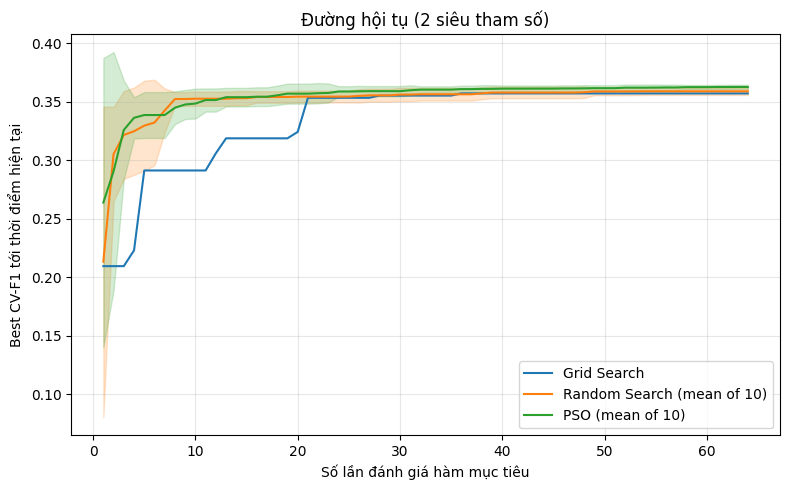

In [15]:
colors = {'Grid Search': 'tab:blue', 'Random Search': 'tab:orange', 'PSO': 'tab:green'}

# (a) Đường hội tụ
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(np.arange(1, len(grid_res['history']) + 1), grid_res['history'], label='Grid Search', color=colors['Grid Search'])
for name, runs in [('Random Search', rand_runs), ('PSO', pso_runs)]:
    H = np.array([r['history'] for r in runs]); m, s = H.mean(0), H.std(0, ddof=1)
    x = np.arange(1, H.shape[1] + 1)
    ax.plot(x, m, label=name + f' (mean of {N_RUNS})', color=colors[name])
    ax.fill_between(x, m - s, m + s, alpha=0.2, color=colors[name])
ax.set_xlabel('Số lần đánh giá hàm mục tiêu'); ax.set_ylabel('Best CV-F1 tới thời điểm hiện tại')
ax.set_title('Đường hội tụ (2 siêu tham số)'); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig('convergence.png', dpi=150); plt.show()

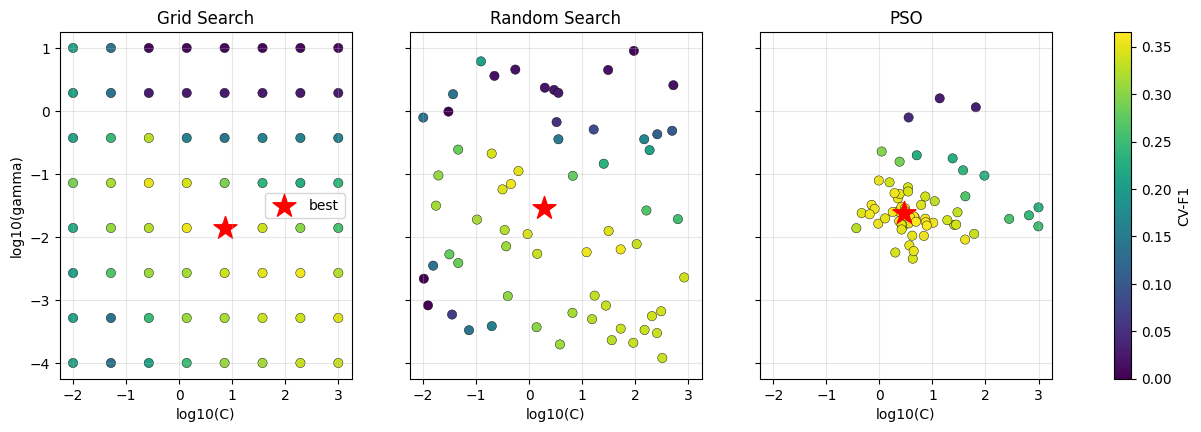

In [16]:
# (b) Các điểm được duyệt trong không gian (log C, log gamma)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
data = [('Grid Search', grid_res), ('Random Search', best_runs['Random Search']), ('PSO', best_runs['PSO'])]
vmin = min(d['scores'].min() for _, d in data); vmax_ = max(d['scores'].max() for _, d in data)
for ax, (name, d) in zip(axes, data):
    sc = ax.scatter(d['points'][:, 0], d['points'][:, 1], c=d['scores'], cmap='viridis',
                    vmin=vmin, vmax=vmax_, s=45, edgecolor='k', linewidth=0.3)
    ax.scatter(np.log10(d['C']), np.log10(d['gamma']), marker='*', s=300, c='red', label='best')
    ax.set_title(name); ax.set_xlabel('log10(C)'); ax.grid(alpha=0.3)
axes[0].set_ylabel('log10(gamma)'); axes[0].legend()
fig.colorbar(sc, ax=axes, label='CV-F1')
plt.savefig('search_space.png', dpi=150, bbox_inches='tight'); plt.show()

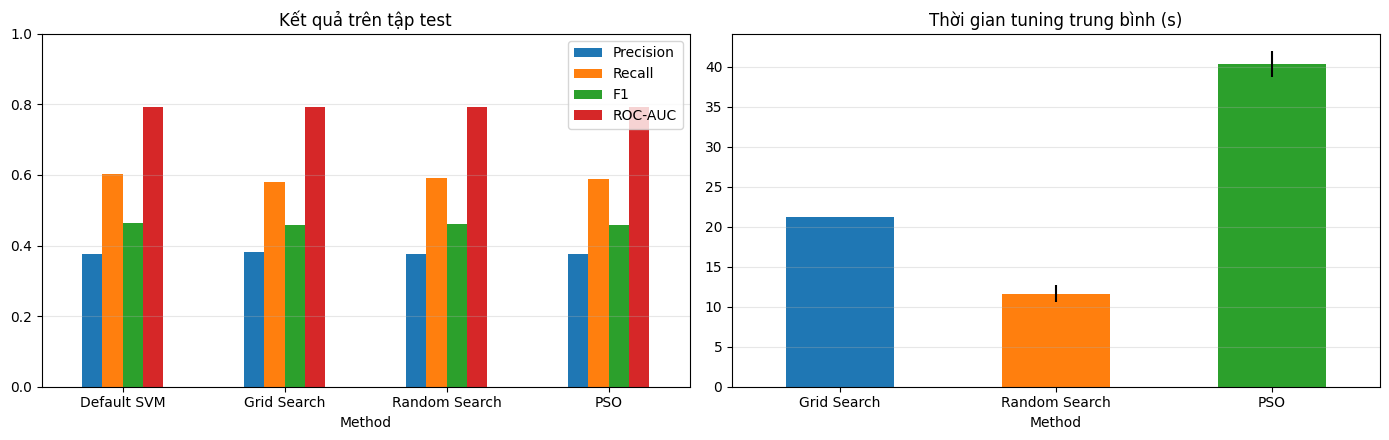

In [17]:
# (c) Chỉ số test và thời gian tuning
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
test_df.set_index('Method')[['Precision', 'Recall', 'F1', 'ROC-AUC']].plot.bar(ax=axes[0], rot=0)
axes[0].set_title('Kết quả trên tập test'); axes[0].set_ylim(0, 1); axes[0].grid(alpha=0.3, axis='y')
tuning_df.set_index('Method')['Time mean (s)'].plot.bar(
    ax=axes[1], rot=0, yerr=tuning_df.set_index('Method')['Time std (s)'],
    color=[colors[m] for m in tuning_df['Method']])
axes[1].set_title('Thời gian tuning trung bình (s)'); axes[1].grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.savefig('test_metrics_time.png', dpi=150); plt.show()

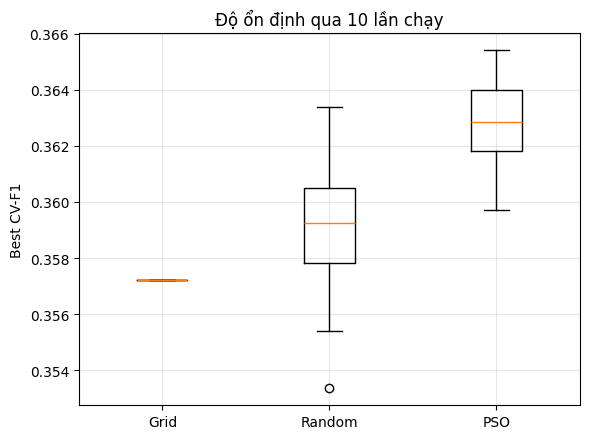

In [18]:
# (d) Độ ổn định qua các lần chạy
plt.figure(figsize=(6, 4.5))
plt.boxplot([[grid_res['cv_score']], rand_scores, pso_scores], labels=['Grid', 'Random', 'PSO'])
plt.ylabel('Best CV-F1'); plt.title(f'Độ ổn định qua {N_RUNS} lần chạy'); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('stability.png', dpi=150); plt.show()

### 10. Lưu kết quả

In [19]:
tuning_df.to_csv('tuning_summary_2params.csv', index=False)
test_df.to_csv('test_results_2params.csv', index=False)
print(tuning_df.to_string(index=False)); print(); print(test_df.round(4).to_string(index=False))

       Method  n_evals  CV-F1 mean  CV-F1 std  CV-F1 best  Time mean (s)  Time std (s)
  Grid Search       64      0.3572     0.0000      0.3572        21.2514        0.0000
Random Search       64      0.3590     0.0031      0.3634        11.6160        1.0733
          PSO       64      0.3627     0.0019      0.3654        40.3702        1.6365

       Method      C     gamma  Accuracy  Precision  Recall     F1  ROC-AUC  Final fit (s)  Tuning time (s)
  Default SVM 1.0000     scale    0.8361     0.3753  0.6030 0.4627   0.7914       101.4068              NaN
  Grid Search 7.1969  0.013895    0.8407     0.3810  0.5794 0.4597   0.7924        96.2774          21.2514
Random Search 1.9164  0.029082    0.8378     0.3767  0.5907 0.4601   0.7928        99.2599          12.0584
          PSO 2.8646  0.024054    0.8382     0.3772  0.5879 0.4595   0.7932        97.7985          42.3656
